# Ablations

In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from neuralzip.model import (
    DEFAULT_JS_THRESHOLD,
    DEFAULT_MAX_HEATMAP_TENSORS,
    DEFAULT_NGRAM_SIZES,
    HFModel,
)
from config import MODEL_SUITE

OUTPUT_DIR = Path("outputs/ablations")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

NGRAM_SIZES = list(DEFAULT_NGRAM_SIZES)
MAX_HEATMAP_TENSORS = DEFAULT_MAX_HEATMAP_TENSORS
JS_THRESHOLD = DEFAULT_JS_THRESHOLD


## Zero-order empirical entropy

In [3]:
entropy_results = []
for model_dict in MODEL_SUITE:
    hf_model = HFModel(
        model_dict["model_id"],
        dtype=model_dict["default_dtype"],
    )
    entropy_results.append(
        {
            "model_id": model_dict["model_id"],
            "model_name": model_dict["name"],
            "model": hf_model,
            **hf_model.compute_zero_order_entropy_summary(),
        }
    )


Loading weights: 100%|██████████| 120/120 [00:00<00:00, 1425.69it/s]
[transformers] ResNetModel LOAD REPORT from: microsoft/resnet-18
Key                 | Status     |  | 
--------------------+------------+--+-
classifier.1.bias   | UNEXPECTED |  | 
classifier.1.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 310.76it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.

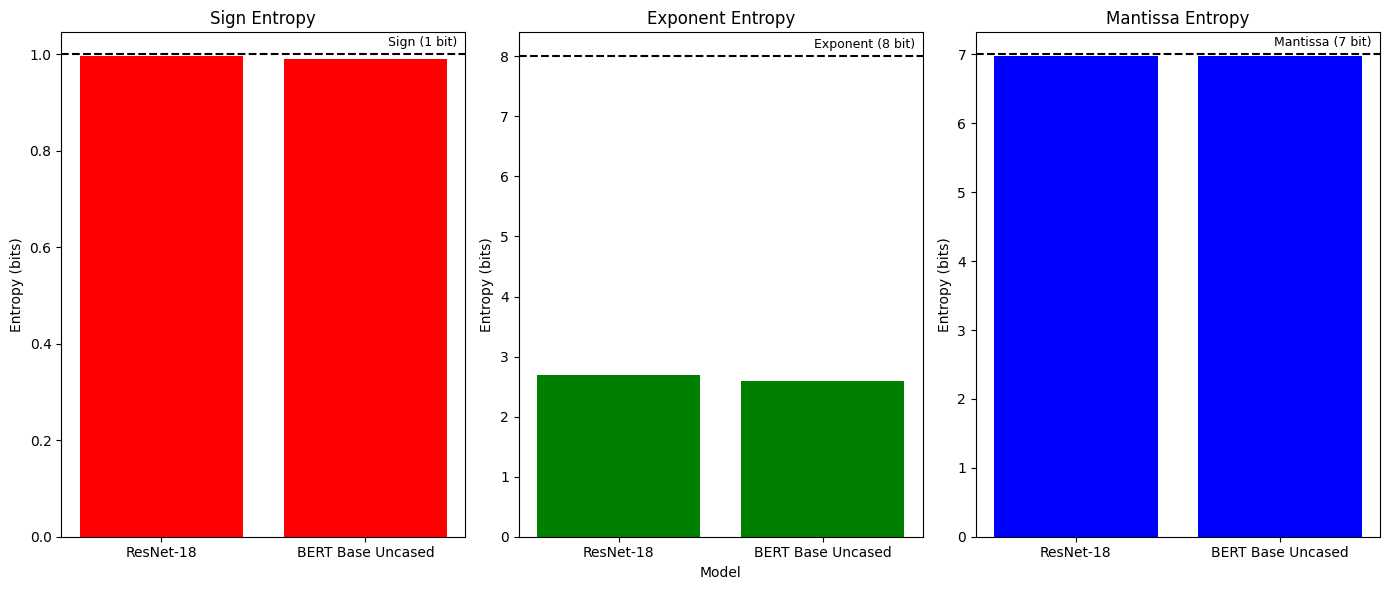

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 6))

axes[0].bar(
    [row["model_name"] for row in entropy_results],
    [row["zero_order_entropy_sign"] for row in entropy_results],
    color="red",
)
axes[0].axhline(1, color="black", linestyle="--")
axes[0].annotate(
    "Sign (1 bit)",
    xy=(0.98, 1),
    xycoords=axes[0].get_yaxis_transform(),
    xytext=(0, 4),
    textcoords="offset points",
    ha="right",
    va="bottom",
    color="black",
    fontsize=9,
)
axes[0].set_title("Sign Entropy")
axes[0].set_ylabel("Entropy (bits)")

axes[1].bar(
    [row["model_name"] for row in entropy_results],
    [row["zero_order_entropy_exponents"] for row in entropy_results],
    color="green",
)
axes[1].axhline(entropy_results[0]["exponent_bits"], color="black", linestyle="--")
axes[1].annotate(
    f"Exponent ({entropy_results[0]['exponent_bits']} bit)",
    xy=(0.98, entropy_results[0]["exponent_bits"]),
    xycoords=axes[1].get_yaxis_transform(),
    xytext=(0, 4),
    textcoords="offset points",
    ha="right",
    va="bottom",
    color="black",
    fontsize=9,
)
axes[1].set_title("Exponent Entropy")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("Entropy (bits)")

axes[2].bar(
    [row["model_name"] for row in entropy_results],
    [row["zero_order_entropy_mantissa"] for row in entropy_results],
    color="blue",
)
axes[2].axhline(entropy_results[0]["mantissa_bits"], color="black", linestyle="--")
axes[2].annotate(
    f"Mantissa ({entropy_results[0]['mantissa_bits']} bit)",
    xy=(0.98, entropy_results[0]["mantissa_bits"]),
    xycoords=axes[2].get_yaxis_transform(),
    xytext=(0, 4),
    textcoords="offset points",
    ha="right",
    va="bottom",
    color="black",
    fontsize=9,
)
axes[2].set_title("Mantissa Entropy")
axes[2].set_ylabel("Entropy (bits)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "zero_order_entropy.pdf", bbox_inches="tight")
plt.show()


## $n$-gram exponents

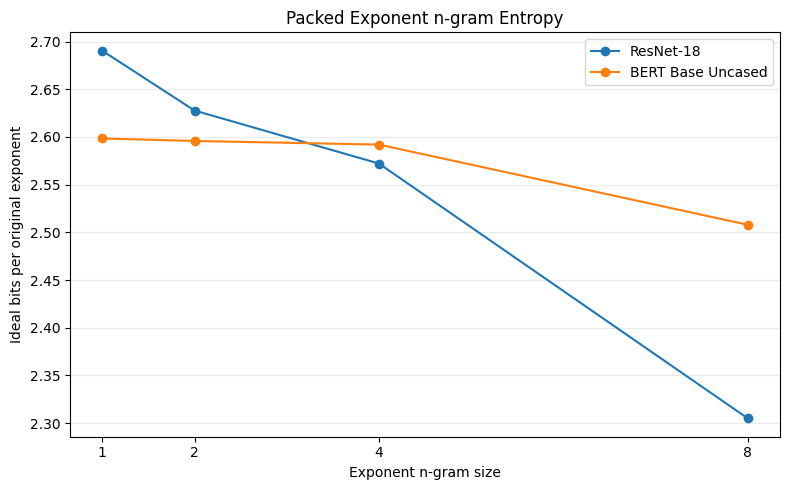

In [8]:
ngram_results = []
for row in entropy_results:
    for result in row["model"].compute_exponent_ngram_entropy(NGRAM_SIZES):
        ngram_results.append(
            {
                "model_name": row["model_name"],
                "model_id": row["model_id"],
                **result,
            }
        )

plt.figure(figsize=(8, 5))
for model_name in [row["model_name"] for row in entropy_results]:
    rows = [row for row in ngram_results if row["model_name"] == model_name]
    plt.plot(
        [row["n"] for row in rows],
        [row["bits_per_exponent"] for row in rows],
        marker="o",
        label=model_name,
    )

plt.xticks(NGRAM_SIZES)
plt.xlabel("Exponent n-gram size")
plt.ylabel("Ideal bits per original exponent")
plt.title("Packed Exponent n-gram Entropy")
plt.grid(axis="y", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ngram_exponent_entropy.pdf", bbox_inches="tight")
plt.show()

## Blockwise heterogeneity

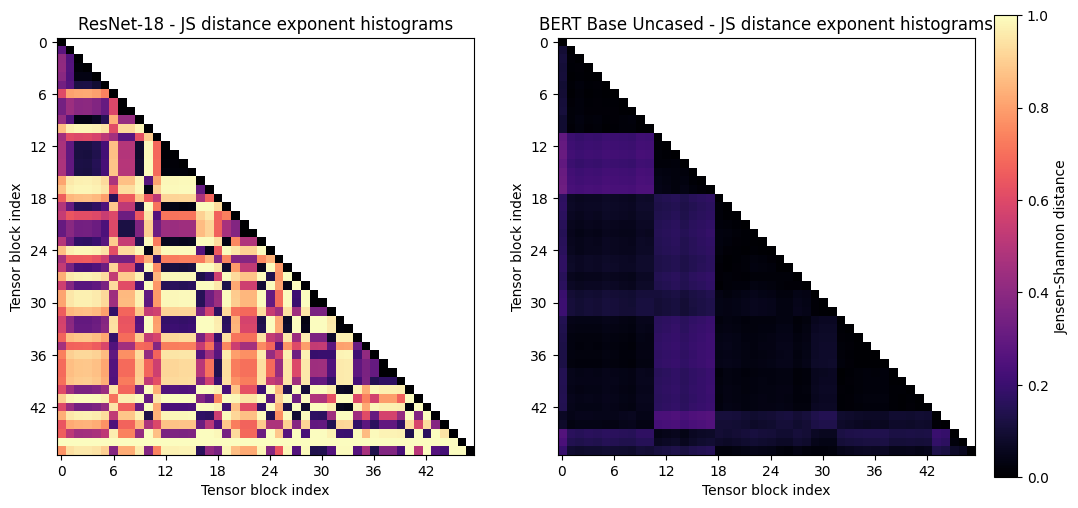

In [9]:
blockwise_summary = []
heatmap_payloads = []
for row in entropy_results:
    heterogeneity = row["model"].compute_blockwise_heterogeneity(
        max_heatmap_tensors=MAX_HEATMAP_TENSORS,
        js_threshold=JS_THRESHOLD,
    )
    blockwise_summary.append(
        {
            "model_name": row["model_name"],
            "model_id": row["model_id"],
            **heterogeneity["summary"],
        }
    )
    heatmap_payloads.append(
        {
            "model_name": row["model_name"],
            "matrix": heterogeneity["js_matrix"],
        }
    )

fig, axes = plt.subplots(
    1,
    len(heatmap_payloads),
    figsize=(6.2 * len(heatmap_payloads), 6),
    squeeze=False,
)
max_distance = max(
    payload["matrix"][np.tril_indices_from(payload["matrix"], k=-1)].max(initial=0.0)
    for payload in heatmap_payloads
)
max_distance = max(max_distance, 1e-9)

for ax, payload in zip(axes[0], heatmap_payloads):
    matrix = payload["matrix"]
    visible_matrix = np.ma.masked_where(np.triu(np.ones_like(matrix), k=1), matrix)
    image = ax.imshow(visible_matrix, cmap="magma", vmin=0, vmax=max_distance)
    ax.set_title(f"{payload['model_name']} - JS distance exponent histograms")
    tick_step = max(1, matrix.shape[0] // 8)
    ticks = np.arange(0, matrix.shape[0], tick_step)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_xticklabels(ticks)
    ax.set_yticklabels(ticks)
    ax.set_xlabel("Tensor block index")
    ax.set_ylabel("Tensor block index")

fig.colorbar(image, ax=axes.ravel().tolist(), fraction=0.025, pad=0.02, label="Jensen-Shannon distance")
fig.savefig(OUTPUT_DIR / "blockwise_js_heatmaps.pdf", bbox_inches="tight")
plt.show()